# Imports

In [67]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import pyepo
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

# Data Generation

In [ ]:
num_data = 30000     # Number of examples
num_features = 5     # Ex: Weather, Day of week, etc
grid_size = (5, 5)   # Number of cities to visit
poly_degree = 4      # The True relation is between x and c is polynomial of degree 4 (Misspecification)

In [48]:
x, c = pyepo.data.shortestpath.genData(num_data=num_data, num_features=num_features, grid=grid_size, deg=poly_degree)
x_train, x_test, c_train, c_test = train_test_split(x, c, test_size=0.2, shuffle=True)

In [49]:
opt_model = pyepo.model.grb.shortestPathModel(grid_size)
dataset_train = pyepo.data.dataset.optDataset(model=opt_model,feats=x_train, costs=c_train) # return i: xi, ci, w*(ci), z*(ci)
dataset_test = pyepo.data.dataset.optDataset(model=opt_model, feats=x_test, costs=c_test) # return i: xi, ci, w*(ci), z*(ci)
loader_train = DataLoader(dataset_train, batch_size=32, shuffle=False)
loader_test = DataLoader(dataset_test, batch_size=32, shuffle=False)

100%|██████████| 6000/6000 [00:00<00:00, 10960.25it/s]


# Models Definition

## Linear Models (Model Misspecification)

- The relation between x and c is non linear (polynomial of degree 4), so we expect that the linear model would be incapable of explaining the data, and in this case we expect to see a considerable difference between SPO+ model and MSE model considering SPO loss ( SPO+ Model considerably better !)

In [50]:
class LinearRegression(nn.Module):
    def __init__(self, num_features, num_edges):
        super().__init__()
        self.num_features = num_features
        self.num_edges = num_edges
        self.linear = nn.Linear(in_features=num_features, out_features=num_edges)
    def forward(self, x):
        return self.linear(x)

In [51]:
num_edges = opt_model.num_cost
linear_model_mse = LinearRegression(num_features=num_features, num_edges=num_edges)
linear_model_spo = LinearRegression(num_features=num_features, num_edges=num_edges)
linear_model_spo.load_state_dict(linear_model_mse.state_dict())

<All keys matched successfully>

## MLP Models (A Richer Hypothesis Space)

- Here we expect the model to be able to explain the relation between x and c, and therefore both models MSE and SPO+ will have small SPO losses.

In [58]:
class SimpleMLP(nn.Module):
    def __init__(self, num_features, num_edges, hidden_dim=64):
        super().__init__()
        self.num_features = num_features
        self.num_edges = num_edges
        self.hidden_dim = hidden_dim
        self.network = nn.Sequential(
            nn.Linear(num_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_edges)
        )
    def forward(self, x):
        return self.network(x)

In [59]:
num_edges = opt_model.num_cost
mlp_model_mse = SimpleMLP(num_features=num_features, num_edges=num_edges)
mlp_model_spo = SimpleMLP(num_features=num_features, num_edges=num_edges)
mlp_model_spo.load_state_dict(mlp_model_mse.state_dict())

<All keys matched successfully>

# Models Training

In [60]:
def train_model(model, dataloader, optmodel, num_epochs, is_spo=False):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
    if is_spo:
        criterion = pyepo.func.SPOPlus(optmodel=optmodel,processes=1)
    else:
        criterion = nn.MSELoss()
    model.train()
    for epoch in range(num_epochs):
        epoch_loss=0
        for data in dataloader:
            x, c, w, z = data
            optimizer.zero_grad()
            c_hat = model(x)

            if is_spo:
                loss = criterion(c_hat, c, w, z)
            else:
                loss = criterion(c_hat, c)
            loss.backward()
            optimizer.step()
            epoch_loss +=loss.item()
        if (epoch+1)%5==0:
            mode = "SPO+" if is_spo else "MSE"
            print(f"[{mode}] Epoch {epoch+1}/{num_epochs} - Loss: {epoch_loss/len(dataloader):.4f}")
    return model


## Linear Models

In [53]:
print("--- Training with MSE loss ---")
linear_model_mse = train_model(model=linear_model_mse, optmodel=opt_model, dataloader=loader_train, num_epochs=30, is_spo=False)

print("--- Training with SPO+ loss ---")
linear_model_spo = train_model(model=linear_model_spo, optmodel=opt_model, dataloader=loader_train, num_epochs=30, is_spo=True)

--- Training with MSE loss ---
[MSE] Epoch 5/30 - Loss: 0.1115
[MSE] Epoch 10/30 - Loss: 0.1115
[MSE] Epoch 15/30 - Loss: 0.1115
[MSE] Epoch 20/30 - Loss: 0.1115
[MSE] Epoch 25/30 - Loss: 0.1115
[MSE] Epoch 30/30 - Loss: 0.1115
--- Training with SPO+ loss ---
[SPO+] Epoch 5/30 - Loss: 0.1426
[SPO+] Epoch 10/30 - Loss: 0.1416
[SPO+] Epoch 15/30 - Loss: 0.1406
[SPO+] Epoch 20/30 - Loss: 0.1415
[SPO+] Epoch 25/30 - Loss: 0.1402
[SPO+] Epoch 30/30 - Loss: 0.1428


## MLP Models

In [61]:
print("--- Training with MSE loss ---")
mlp_model_mse = train_model(model=mlp_model_mse, optmodel=opt_model, dataloader=loader_train, num_epochs=30, is_spo=False)

print("--- Training with SPO+ loss ---")
mlp_model_spo = train_model(model=mlp_model_spo, optmodel=opt_model, dataloader=loader_train, num_epochs=30, is_spo=True)

--- Training with MSE loss ---
[MSE] Epoch 5/30 - Loss: 0.0035
[MSE] Epoch 10/30 - Loss: 0.0032
[MSE] Epoch 15/30 - Loss: 0.0030
[MSE] Epoch 20/30 - Loss: 0.0034
[MSE] Epoch 25/30 - Loss: 0.0032
[MSE] Epoch 30/30 - Loss: 0.0033
--- Training with SPO+ loss ---
[SPO+] Epoch 5/30 - Loss: 0.1397
[SPO+] Epoch 10/30 - Loss: 0.1360
[SPO+] Epoch 15/30 - Loss: 0.1336
[SPO+] Epoch 20/30 - Loss: 0.1376
[SPO+] Epoch 25/30 - Loss: 0.1320
[SPO+] Epoch 30/30 - Loss: 0.1295


# Comparing Losses

## Linear Models

In [62]:
linear_model_mse.eval()
linear_model_spo.eval()

mse_loss = nn.MSELoss()
with torch.no_grad():
    x_test_ts = torch.FloatTensor(x_test)
    c_test_ts = torch.FloatTensor(c_test)
    mse_error_linear_model_mse = mse_loss(linear_model_mse(x_test_ts), c_test_ts)
    mse_error_linear_model_spo = mse_loss(linear_model_spo(x_test_ts), c_test_ts)

print(f"MSE Error :")
print(f" - Model  MSE  : {mse_error_linear_model_mse:.4f}")
print(f" - Model SPO+ : {mse_error_linear_model_spo:.4f}")

MSE Error :
 - Model  MSE  : 0.1121
 - Model SPO+ : 1.3120


In [63]:
regret_linear_model_mse = pyepo.metric.regret(linear_model_mse, opt_model, loader_test)
regret_linear_model_spo = pyepo.metric.regret(linear_model_spo, opt_model, loader_test)

print(f"\n SPO Error :")
print(f" - Model MSE : {regret_linear_model_mse:.4f}")
print(f" - Model SPO+ : {regret_linear_model_spo:.4f}")


 SPO Error :
 - Model MSE : 0.0191
 - Model SPO+ : 0.0045


## MLP Models

In [64]:
mlp_model_mse.eval()
mlp_model_spo.eval()

mse_loss = nn.MSELoss()
with torch.no_grad():
    x_test_ts = torch.FloatTensor(x_test)
    c_test_ts = torch.FloatTensor(c_test)
    mse_error_mlp_model_mse = mse_loss(mlp_model_mse(x_test_ts), c_test_ts)
    mse_error_mlp_model_spo = mse_loss(mlp_model_spo(x_test_ts), c_test_ts)

print(f"MSE Error :")
print(f" - Model  MSE  : {mse_error_mlp_model_mse:.4f}")
print(f" - Model SPO+ : {mse_error_mlp_model_spo:.4f}")

MSE Error :
 - Model  MSE  : 0.0024
 - Model SPO+ : 1.5107


In [65]:
regret_mlp_model_mse = pyepo.metric.regret(mlp_model_mse, opt_model, loader_test)
regret_mlp_model_spo = pyepo.metric.regret(mlp_model_spo, opt_model, loader_test)

print(f"\n SPO Error :")
print(f" - Model MSE : {regret_mlp_model_mse:.4f}")
print(f" - Model SPO+ : {regret_mlp_model_spo:.4f}")


 SPO Error :
 - Model MSE : 0.0028
 - Model SPO+ : 0.0044


## Analysis

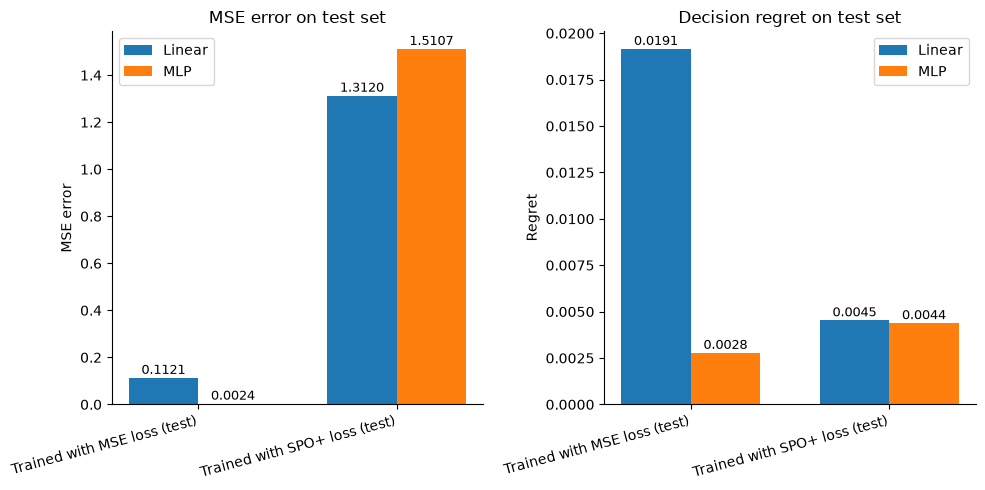

In [69]:
labels   = ["Trained with MSE loss (test)", "Trained with SPO+ loss (test)"]
lin_model_mse_vals = [mse_error_linear_model_mse, mse_error_linear_model_spo]
lin_model_regret_vals = [regret_linear_model_mse, regret_linear_model_spo]
mlp_model_mse_vals = [mse_error_mlp_model_mse, mse_error_mlp_model_spo]
mlp_model_regret_vals = [regret_mlp_model_mse, regret_mlp_model_spo]


x     = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# ---------- graphe 1 : MSE error ----------
ax = axes[0]
b1 = ax.bar(x - width/2, lin_model_mse_vals, width, label="Linear", color="tab:blue")
b2 = ax.bar(x + width/2, mlp_model_mse_vals, width, label="MLP",    color="tab:orange")

for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{b.get_height():.4f}",
                    xy=(b.get_x() + b.get_width()/2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylabel("MSE error")
ax.set_title("MSE error on test set")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

# ---------- graphe 2 : Regret ----------
ax = axes[1]
b3 = ax.bar(x - width/2, lin_model_regret_vals, width, label="Linear", color="tab:blue")
b4 = ax.bar(x + width/2, mlp_model_regret_vals, width, label="MLP",    color="tab:orange")

for bars in (b3, b4):
    for b in bars:
        ax.annotate(f"{b.get_height():.4f}",
                    xy=(b.get_x() + b.get_width()/2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylabel("Regret")
ax.set_title("Decision regret on test set")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()